In [ ]:
## Cylindrical Bottle Panorama — Sequential Stitching & Visual Analysis

In [ ]:
#1. Imports and configuration

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

IMAGE_PATHS = ["cam_1.png", "cam_2.png", "cam_3.png", "cam_4.png"]
OUTPUT_DIR = Path("stitch_4_images")
OUTPUT_DIR.mkdir(exist_ok=True)

SIFT_FEATURES = 8000
RATIO_TEST = 0.68
RANSAC_THRESHOLD = 2.5
SOFT_EDGE = 12

# Set to True to display detailed SIFT match plots for every adjacent pair.
SHOW_MATCH_DETAILS = True

def to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def show_image(img, title="", cmap=None, figsize=(8, 6)):
    plt.figure(figsize=figsize)
    if img.ndim == 2:
        plt.imshow(img, cmap=cmap or "gray")
    else:
        plt.imshow(to_rgb(img))
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


In [ ]:
# 2. Load and inspect the four input images

Loaded cam_1.png: width=2448, height=2048, channels=3
Loaded cam_2.png: width=2448, height=2048, channels=3
Loaded cam_3.png: width=2448, height=2048, channels=3
Loaded cam_4.png: width=2448, height=2048, channels=3


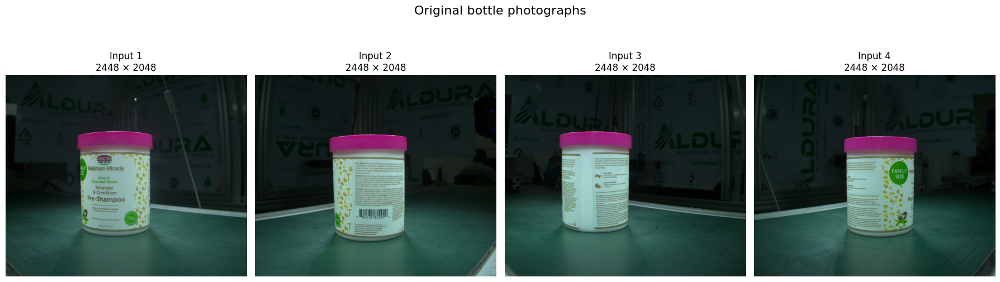

In [2]:
images = []
for path in IMAGE_PATHS:
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(
            f"Could not load '{path}'. Put the image beside this notebook or update IMAGE_PATHS."
        )
    images.append(img)
    print(f"Loaded {path}: width={img.shape[1]}, height={img.shape[0]}, channels={img.shape[2]}")

if len(images) != 4:
    raise ValueError(f"Expected 4 images, found {len(images)}")

fig, axes = plt.subplots(1, 4, figsize=(18, 6))
for i, (ax, img) in enumerate(zip(axes, images)):
    ax.imshow(to_rgb(img))
    ax.set_title(f"Input {i+1}\n{img.shape[1]} × {img.shape[0]}")
    ax.axis("off")
plt.suptitle("Original bottle photographs", fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:
#3. SIFT feature detection and matching

In [8]:

def sift_match_details(img1, img2, ratio=RATIO_TEST):

    sift = cv2.SIFT_create(nfeatures=SIFT_FEATURES)

    kp1, des1 = sift.detectAndCompute(img1, None)
    kp2, des2 = sift.detectAndCompute(img2, None)

    if des1 is None or des2 is None:
        raise RuntimeError("SIFT descriptors not found.")

    matcher = cv2.BFMatcher(cv2.NORM_L2)

    # Match image 2 descriptors against image 1 descriptors
    pairs = matcher.knnMatch(des2, des1, k=2)

    good = [
        m for pair in pairs if len(pair) == 2
        for m, n in [pair]
        if m.distance < ratio * n.distance
    ]

    if len(good) < 12:
        raise RuntimeError(f"Too few good matches: {len(good)}")

    # Image 2 = source, Image 1 = destination
    src = np.float32([
        kp2[m.queryIdx].pt for m in good
    ]).reshape(-1, 1, 2)

    dst = np.float32([
        kp1[m.trainIdx].pt for m in good
    ]).reshape(-1, 1, 2)

    M, inlier_mask = cv2.estimateAffinePartial2D(
        src,
        dst,
        method=cv2.RANSAC,
        ransacReprojThreshold=RANSAC_THRESHOLD,
        maxIters=5000,
        confidence=0.995
    )

    if M is None or inlier_mask is None:
        raise RuntimeError("RANSAC estimation failed.")

    inliers = inlier_mask.ravel().astype(bool)

    # Explicitly validate match indices
    valid_matches = []

    for m in good:
        if (0 <= m.queryIdx < len(kp2) and
            0 <= m.trainIdx < len(kp1)):
            valid_matches.append(m)

    if len(valid_matches) != len(good):
        raise RuntimeError("Invalid SIFT match indices detected.")

    H = np.vstack([M, [0, 0, 1]]).astype(np.float64)

    stats = {
        "keypoints_1": len(kp1),
        "keypoints_2": len(kp2),
        "good_matches": len(good),
        "inliers": int(inliers.sum()),
        "inlier_ratio": float(inliers.mean()),
        "H": H
    }

    return kp1, kp2, good, inliers, stats


In [5]:
#3A. Visualize feature matches between the original adjacent images


Image 1 → Image 2
Good matches: 115
Inliers: 13
Inlier ratio: 11.30%


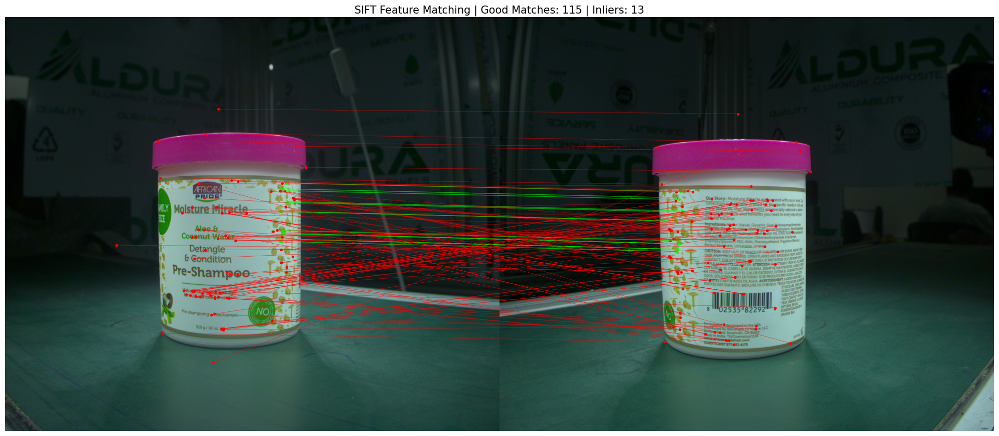


Image 2 → Image 3
Good matches: 200
Inliers: 36
Inlier ratio: 18.00%


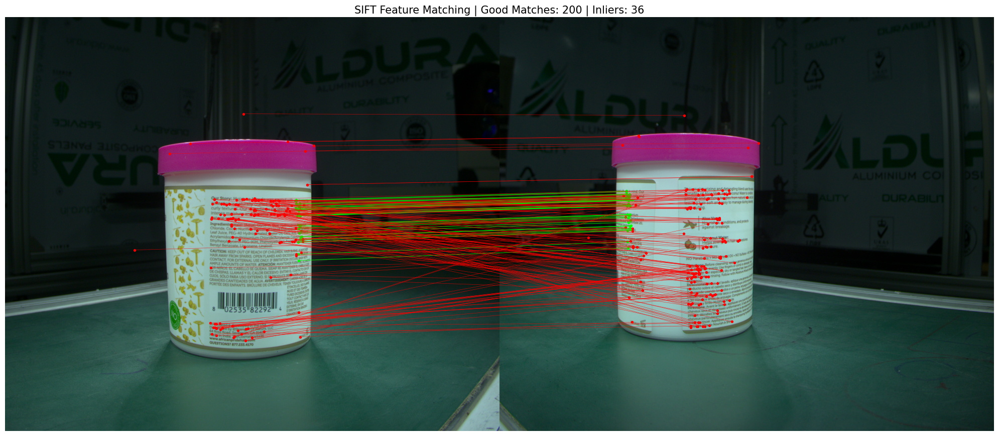


Image 3 → Image 4
Good matches: 192
Inliers: 40
Inlier ratio: 20.83%


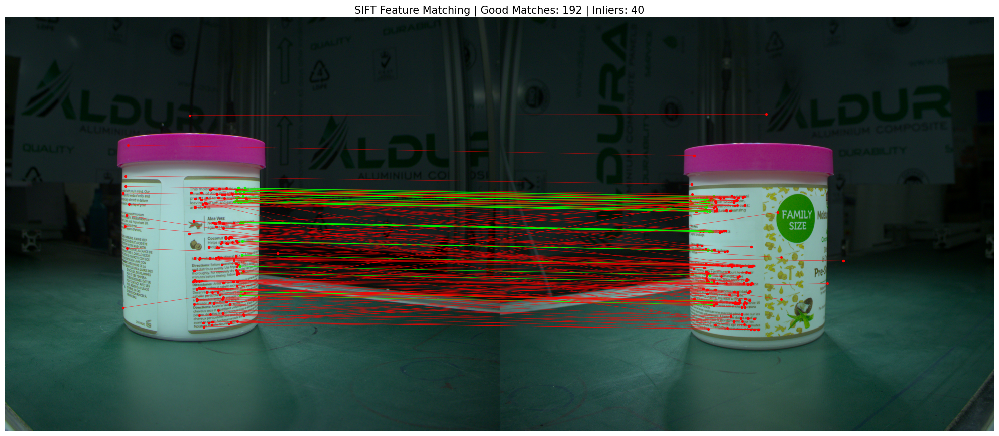

In [11]:

def visualize_matches(img1, img2, kp1, kp2, good, inliers):

    # Convert images to RGB
    img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
    img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]

    # Create side-by-side canvas
    canvas = np.zeros(
        (max(h1, h2), w1 + w2, 3),
        dtype=np.uint8
    )

    canvas[:h1, :w1] = img1_rgb
    canvas[:h2, w1:w1+w2] = img2_rgb

    plt.figure(figsize=(20, 10))
    plt.imshow(canvas)

    for match, is_inlier in zip(good, inliers):

        # Match coordinates
        x1, y1 = kp1[match.trainIdx].pt
        x2, y2 = kp2[match.queryIdx].pt

        # Shift second image coordinates
        x2 += w1

        if is_inlier:
            color = "lime"
            linewidth = 0.9
        else:
            color = "red"
            linewidth = 0.5

        plt.plot(
            [x1, x2],
            [y1, y2],
            color=color,
            linewidth=linewidth,
            alpha=0.7
        )

        plt.scatter([x1, x2], [y1, y2],
                    color=color, s=8)

    plt.title(
        f"SIFT Feature Matching | "
        f"Good Matches: {len(good)} | "
        f"Inliers: {sum(inliers)}",
        fontsize=15
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


# Visualize all three image pairs

for i in range(1, len(images)):

    print(f"\nImage {i} → Image {i+1}")

    kp1, kp2, good, inliers, stats = sift_match_details(
        images[i-1], images[i]
    )

    print("Good matches:", stats["good_matches"])
    print("Inliers:", stats["inliers"])
    print(f"Inlier ratio: {stats['inlier_ratio']:.2%}")

    visualize_matches(
        images[i-1],
        images[i],
        kp1,
        kp2,
        good,
        inliers
    )


In [ ]:
# 4. Bottle-mask creation

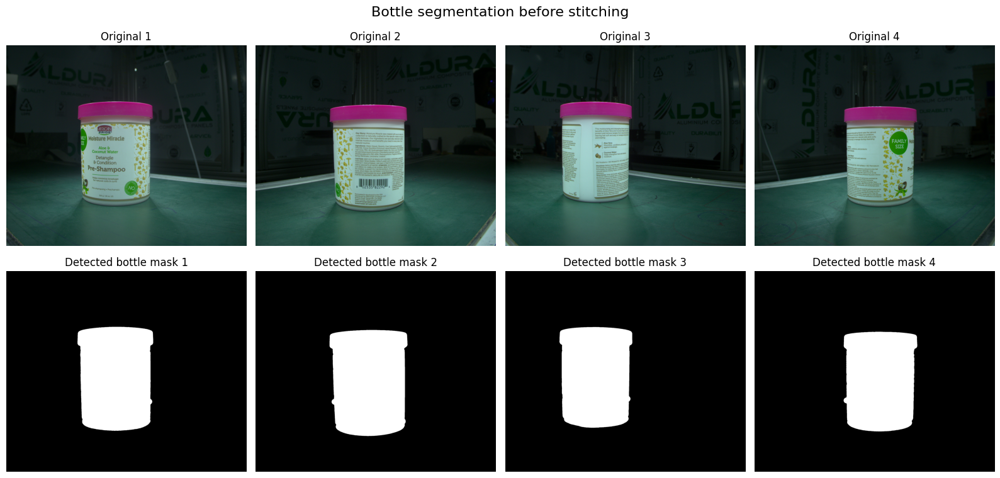

In [12]:
def create_bottle_mask(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    mask = (
        cv2.inRange(hsv, (0, 0, 110), (180, 80, 255)) |
        cv2.inRange(hsv, (0, 0, 125), (180, 255, 255)) |
        cv2.inRange(hsv, (45, 150, 100), (66, 255, 255)) |
        cv2.inRange(hsv, (158, 35, 70), (180, 100, 255)) |
        cv2.inRange(hsv, (140, 110, 70), (175, 255, 255))
    )

    k = lambda n: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (n, n))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k(15), iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k(51))

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        largest = max(contours, key=cv2.contourArea)
        mask = np.zeros_like(mask)
        cv2.drawContours(mask, [largest], -1, 255, -1)

    mask = cv2.dilate(mask, k(9))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k(15))
    return mask > 0

masks = [create_bottle_mask(img) for img in images]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i in range(4):
    axes[0, i].imshow(to_rgb(images[i]))
    axes[0, i].set_title(f"Original {i+1}")
    axes[0, i].axis("off")
    axes[1, i].imshow(masks[i], cmap="gray")
    axes[1, i].set_title(f"Detected bottle mask {i+1}")
    axes[1, i].axis("off")
plt.suptitle("Bottle segmentation before stitching", fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:
# 5. Mask-based clean merge

In [13]:
def clean_merge(w1, w2, m1, m2, soft_edge=12):
    only1 = m1 & ~m2
    only2 = m2 & ~m1
    overlap = m1 & m2

    result = np.zeros_like(w1, dtype=np.float32)
    result[only1] = w1[only1]
    result[only2] = w2[only2]

    if soft_edge <= 0 or overlap.sum() == 0:
        result[overlap] = w1[overlap]
        return np.clip(result, 0, 255).astype(np.uint8)

    dist1 = cv2.distanceTransform(m1.astype(np.uint8), cv2.DIST_L2, 5)
    dist2 = cv2.distanceTransform(m2.astype(np.uint8), cv2.DIST_L2, 5)
    alpha = dist1 / (dist1 + dist2 + 1e-6)
    alpha = cv2.GaussianBlur(
        alpha.astype(np.float32), (soft_edge*2+1, soft_edge*2+1), 0
    )
    alpha = alpha[..., None]

    result[overlap] = (
        w1[overlap] * alpha[overlap] +
        w2[overlap] * (1 - alpha[overlap])
    )
    return np.clip(result, 0, 255).astype(np.uint8)


In [ ]:
# 6. Stitching one image onto the current panorama

In [14]:
def stitch_two(base, new_img, soft_edge=15, return_debug=False):
    H = detect_and_match_sift(base, new_img)

    h1, w1 = base.shape[:2]
    h2, w2 = new_img.shape[:2]

    corners1 = np.float32([[0,0], [w1,0], [w1,h1], [0,h1]]).reshape(-1,1,2)
    corners2 = np.float32([[0,0], [w2,0], [w2,h2], [0,h2]]).reshape(-1,1,2)
    corners2_w = cv2.perspectiveTransform(corners2, H)

    all_c = np.concatenate([corners1, corners2_w], axis=0)
    min_xy = np.floor(all_c.min(0).ravel()).astype(int)
    max_xy = np.ceil(all_c.max(0).ravel()).astype(int)

    width = int(max_xy[0] - min_xy[0])
    height = int(max_xy[1] - min_xy[1])
    if width <= 0 or height <= 0:
        raise RuntimeError("Invalid panorama canvas dimensions.")

    T = np.array([
        [1, 0, -min_xy[0]],
        [0, 1, -min_xy[1]],
        [0, 0, 1]
    ], dtype=np.float64)

    warped_base = cv2.warpPerspective(base, T, (width, height))
    warped_new = cv2.warpPerspective(new_img, T @ H, (width, height))

    mask_base = create_bottle_mask(warped_base) & (
        cv2.cvtColor(warped_base, cv2.COLOR_BGR2GRAY) > 8
    )
    mask_new = create_bottle_mask(warped_new) & (
        cv2.cvtColor(warped_new, cv2.COLOR_BGR2GRAY) > 8
    )

    merged = clean_merge(
        warped_base, warped_new, mask_base, mask_new, soft_edge=soft_edge
    )

    gray = cv2.cvtColor(merged, cv2.COLOR_BGR2GRAY)
    coords = cv2.findNonZero((gray > 5).astype(np.uint8))
    if coords is not None:
        x, y, w, h = cv2.boundingRect(coords)
        merged = merged[y:y+h, x:x+w]

    debug = {
        "H": H,
        "warped_base": warped_base,
        "warped_new": warped_new,
        "mask_base": mask_base,
        "mask_new": mask_new,
        "merged_canvas": merged
    }
    return (merged, debug) if return_debug else merged


In [ ]:
# 7. Inspect each pairwise merge

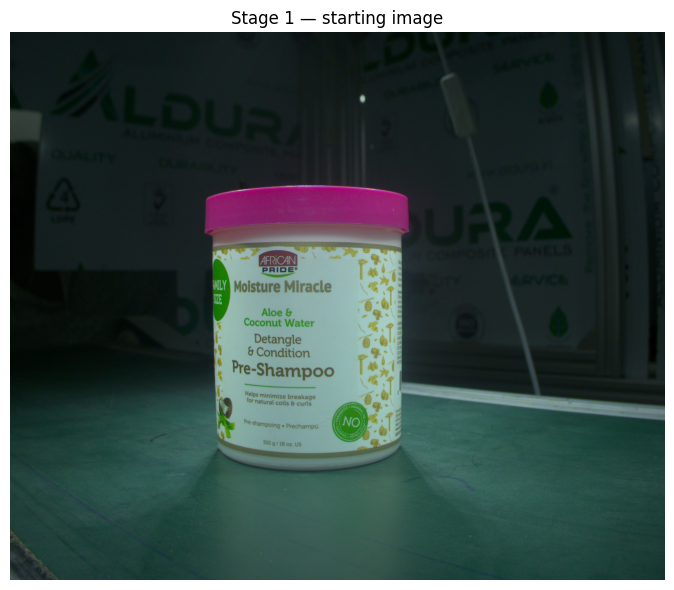


================== Adding image 2 ==================
  Keypoints: 2323 / 6477 | Good matches: 115 | RANSAC inliers: 13 (11.3%)
Saved stitch_4_images\stage_1_to_2.png — 1301 × 1062


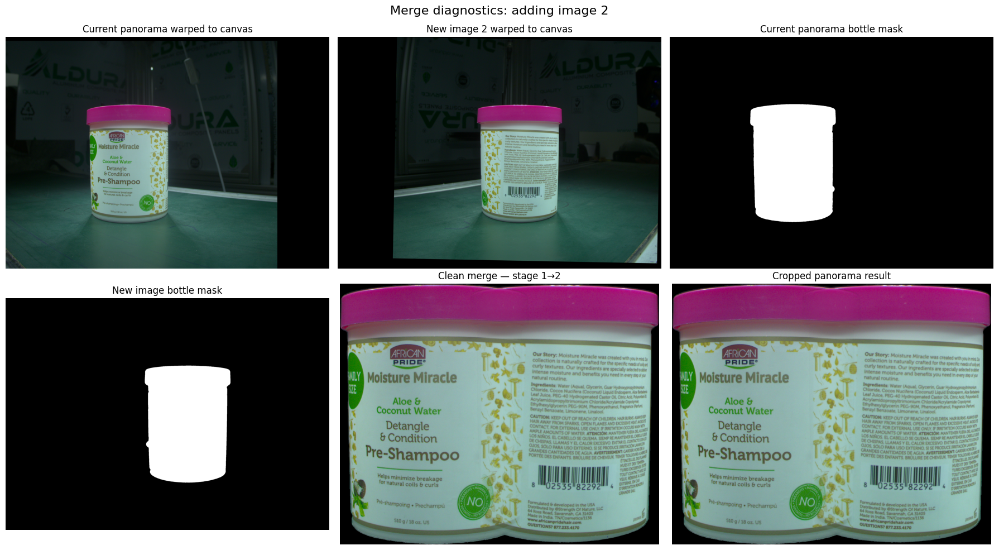


================== Adding image 3 ==================
  Keypoints: 7250 / 5556 | Good matches: 207 | RANSAC inliers: 27 (13.0%)
Saved stitch_4_images\stage_1_to_3.png — 1877 × 1062


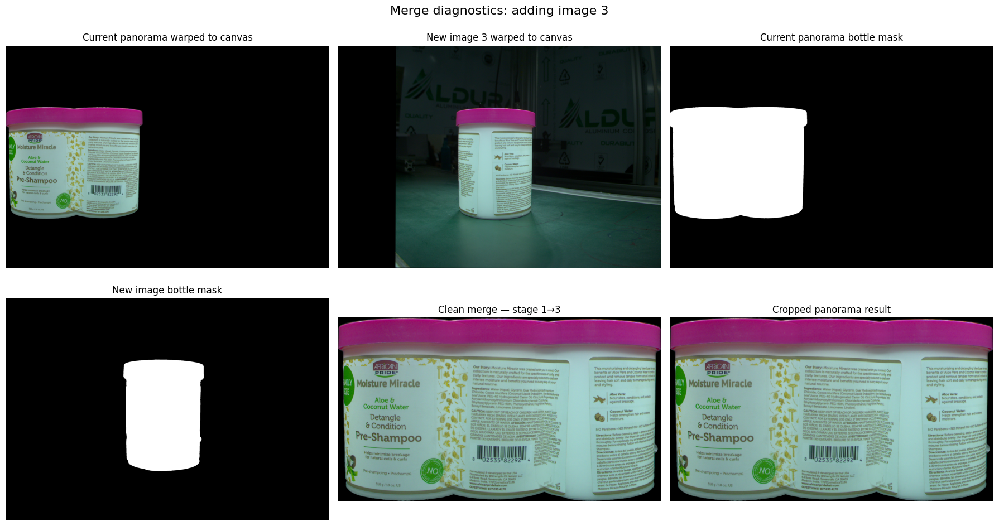


================== Adding image 4 ==================
  Keypoints: 8000 / 3473 | Good matches: 217 | RANSAC inliers: 40 (18.4%)
Saved stitch_4_images\stage_1_to_4.png — 2385 × 1062


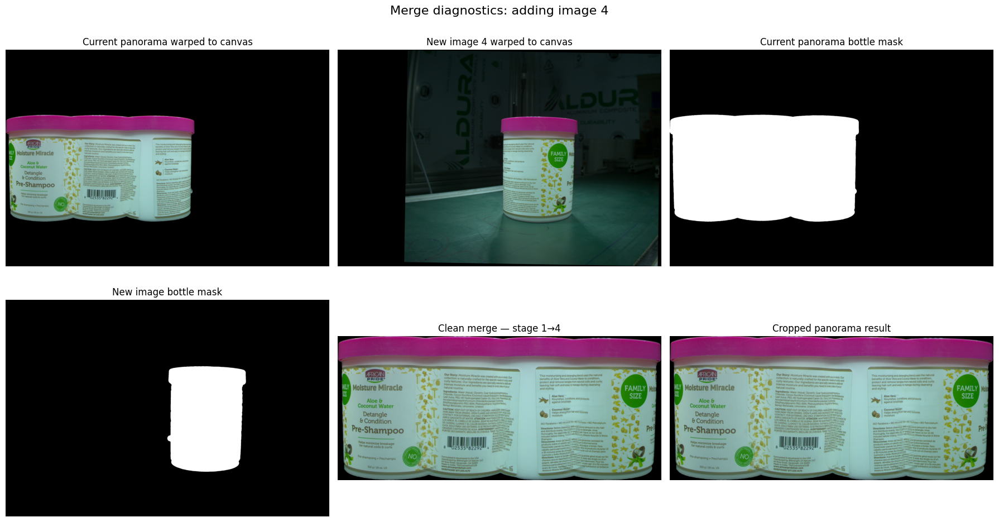

In [15]:
panorama = images[0].copy()
stages = [panorama.copy()]
merge_debug = []

show_image(panorama, "Stage 1 — starting image")

for i in range(1, len(images)):
    print(f"\n{'='*18} Adding image {i+1} {'='*18}")
    panorama, debug = stitch_two(
        panorama, images[i], soft_edge=SOFT_EDGE, return_debug=True
    )
    merge_debug.append(debug)
    stages.append(panorama.copy())

    # Save each intermediate stage
    stage_path = OUTPUT_DIR / f"stage_1_to_{i+1}.png"
    cv2.imwrite(str(stage_path), panorama)
    print(f"Saved {stage_path} — {panorama.shape[1]} × {panorama.shape[0]}")

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes[0, 0].imshow(to_rgb(debug["warped_base"]))
    axes[0, 0].set_title("Current panorama warped to canvas")
    axes[0, 1].imshow(to_rgb(debug["warped_new"]))
    axes[0, 1].set_title(f"New image {i+1} warped to canvas")
    axes[0, 2].imshow(debug["mask_base"], cmap="gray")
    axes[0, 2].set_title("Current panorama bottle mask")
    axes[1, 0].imshow(debug["mask_new"], cmap="gray")
    axes[1, 0].set_title("New image bottle mask")
    axes[1, 1].imshow(to_rgb(debug["merged_canvas"]))
    axes[1, 1].set_title(f"Clean merge — stage 1→{i+1}")
    axes[1, 2].imshow(to_rgb(panorama))
    axes[1, 2].set_title("Cropped panorama result")
    for ax in axes.ravel():
        ax.axis("off")
    plt.suptitle(f"Merge diagnostics: adding image {i+1}", fontsize=16)
    plt.tight_layout()
    plt.show()


In [ ]:
# 8. Cumulative panorama: all four stages

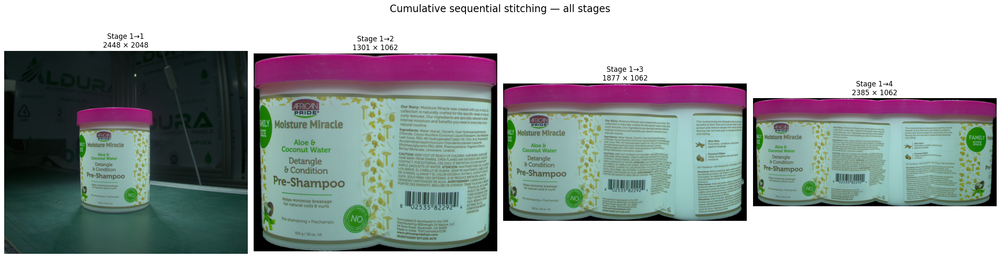

In [16]:
fig, axes = plt.subplots(1, len(stages), figsize=(6*len(stages), 7))
for idx, (ax, stage) in enumerate(zip(axes, stages)):
    ax.imshow(to_rgb(stage))
    ax.set_title(f"Stage 1→{idx+1}\n{stage.shape[1]} × {stage.shape[0]}")
    ax.axis("off")
plt.suptitle("Cumulative sequential stitching — all stages", fontsize=17)
plt.tight_layout()
plt.show()


In [ ]:
# 9. Final panorama and saved outputs

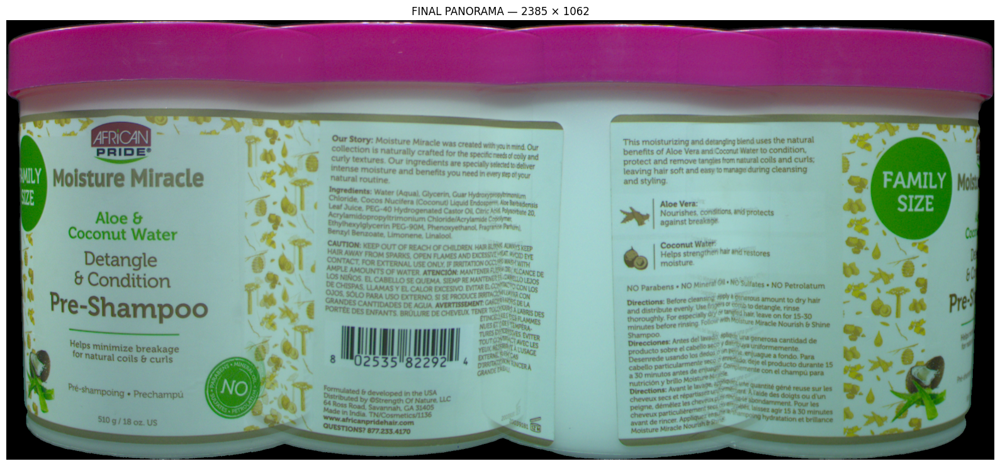

Final panorama: C:\Users\91976\Juypter Notebook work file\Untitled Folder\stitch_4_images\final_panorama.png
Intermediate stages:
 - C:\Users\91976\Juypter Notebook work file\Untitled Folder\stitch_4_images\stage_1_to_2.png
 - C:\Users\91976\Juypter Notebook work file\Untitled Folder\stitch_4_images\stage_1_to_3.png
 - C:\Users\91976\Juypter Notebook work file\Untitled Folder\stitch_4_images\stage_1_to_4.png


In [17]:
final_path = OUTPUT_DIR / "final_panorama.png"
cv2.imwrite(str(final_path), stages[-1])

show_image(stages[-1], f"FINAL PANORAMA — {stages[-1].shape[1]} × {stages[-1].shape[0]}",
           figsize=(16, 8))

print("Final panorama:", final_path.resolve())
print("Intermediate stages:")
for p in sorted(OUTPUT_DIR.glob("stage_*.png")):
    print(" -", p.resolve())


In [ ]:
# 10. Cumulative contribution canvas (visual explanation)

Estimating placement: image 2 → image 1
  Keypoints: 2323 / 6477 | Good matches: 115 | RANSAC inliers: 13 (11.3%)
Estimating placement: image 3 → image 2
  Keypoints: 6477 / 5556 | Good matches: 200 | RANSAC inliers: 36 (18.0%)
Estimating placement: image 4 → image 3
  Keypoints: 5556 / 3473 | Good matches: 192 | RANSAC inliers: 40 (20.8%)


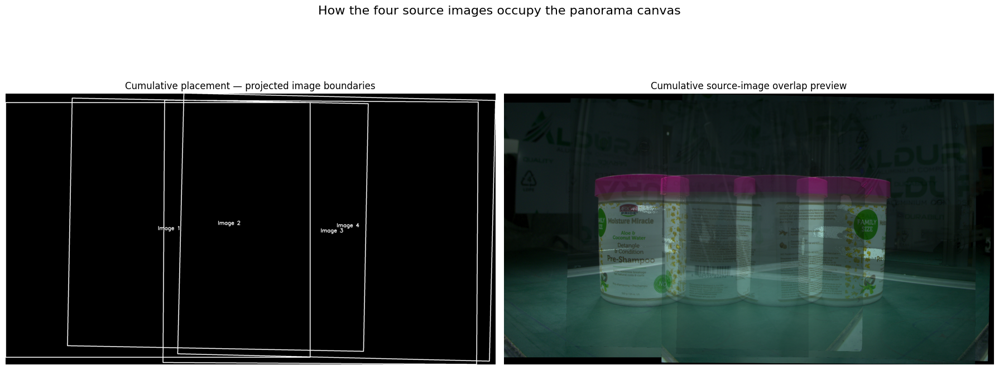

Saved cumulative placement visualizations in: C:\Users\91976\Juypter Notebook work file\Untitled Folder\stitch_4_images


In [18]:
# Rebuild the chain of transforms in the final panorama coordinate system.
# Each pairwise transform maps the newly added image into the previous panorama.
# We retain the transform and canvas translation from each step for this visualization.

def estimate_pair_transform(img1, img2):
    return detect_and_match_sift(img1, img2)

# Compose the adjacent-image transforms in a shared coordinate system.
# This uses the same adjacent input pairs to make the contribution layout easy to interpret.
pair_H = []
for i in range(1, len(images)):
    print(f"Estimating placement: image {i+1} → image {i}")
    pair_H.append(estimate_pair_transform(images[i-1], images[i]))


to_first = [np.eye(3, dtype=np.float64)]
for H in pair_H:
    to_first.append(to_first[-1] @ H)

all_corners = []
for img, H in zip(images, to_first):
    h, w = img.shape[:2]
    corners = np.float32([[0,0], [w,0], [w,h], [0,h]]).reshape(-1,1,2)
    all_corners.append(cv2.perspectiveTransform(corners, H))

all_corners = np.concatenate(all_corners, axis=0)
min_xy = np.floor(all_corners.min(axis=0).ravel()).astype(int)
max_xy = np.ceil(all_corners.max(axis=0).ravel()).astype(int)
canvas_w, canvas_h = (max_xy - min_xy).astype(int)
T = np.array([[1,0,-min_xy[0]], [0,1,-min_xy[1]], [0,0,1]], dtype=np.float64)

# Draw each projected image boundary and a numbered center label.
canvas = np.zeros((canvas_h, canvas_w, 3), dtype=np.uint8)
boundary_view = np.zeros_like(canvas)
for idx, (img, H) in enumerate(zip(images, to_first)):
    h, w = img.shape[:2]
    corners = np.float32([[0,0], [w,0], [w,h], [0,h]]).reshape(-1,1,2)
    projected = cv2.perspectiveTransform(corners, T @ H).astype(np.int32)
    cv2.polylines(boundary_view, [projected], True, (255,255,255), 5)
    center = cv2.perspectiveTransform(
        np.float32([[[w/2, h/2]]]), T @ H
    )[0,0].astype(int)
    cv2.putText(boundary_view, f"Image {idx+1}", tuple(center),
                cv2.FONT_HERSHEY_SIMPLEX, 1.4, (255,255,255), 3, cv2.LINE_AA)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].imshow(to_rgb(boundary_view))
axes[0].set_title("Cumulative placement — projected image boundaries")
axes[0].axis("off")

# Display a thumbnail-sized blend of all four projected source images.
thumb_scale = min(1.0, 1800 / max(canvas_w, canvas_h))
preview_w = max(1, int(canvas_w * thumb_scale))
preview_h = max(1, int(canvas_h * thumb_scale))
preview = np.zeros((preview_h, preview_w, 3), dtype=np.float32)
weight = np.zeros((preview_h, preview_w), dtype=np.float32)
S = np.array([[thumb_scale,0,0], [0,thumb_scale,0], [0,0,1]], dtype=np.float64)
for img, H in zip(images, to_first):
    warped = cv2.warpPerspective(img, S @ T @ H, (preview_w, preview_h))
    valid = (cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY) > 5)
    preview[valid] += warped[valid].astype(np.float32)
    weight[valid] += 1
valid = weight > 0
preview[valid] /= weight[valid, None]
preview = np.clip(preview, 0, 255).astype(np.uint8)

axes[1].imshow(to_rgb(preview))
axes[1].set_title("Cumulative source-image overlap preview")
axes[1].axis("off")
plt.suptitle("How the four source images occupy the panorama canvas", fontsize=16)
plt.tight_layout()
plt.show()

cv2.imwrite(str(OUTPUT_DIR / "cumulative_boundaries.png"), boundary_view)
cv2.imwrite(str(OUTPUT_DIR / "cumulative_overlap_preview.png"), preview)
print("Saved cumulative placement visualizations in:", OUTPUT_DIR.resolve())
